# Benchmark Diversity & Comprehensiveness Analysis

This notebook computes **Diversity** (semantic, structural, complexity spread) and **Comprehensiveness** (class / property / feature coverage) metrics for two NL2SPARQL benchmarks, and generates three publication-ready figures.

In [32]:
import os, json

# Prevent tokenizers / OpenMP from crashing the kernel on macOS
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

from sentence_transformers import SentenceTransformer

from metrics import measure_diversity, measure_comprehensiveness, measure_redundancy
from plots import plot_semantic_embeddings, plot_structural_diversity, plot_comprehensiveness_radar, plot_redundancy, plot_coverage_table

os.makedirs("figures", exist_ok=True)

sbert = SentenceTransformer("BAAI/bge-large-en-v1.5")

## 1. Load Benchmark Data
Provide the paths to the two JSONL benchmark files and the KG name (must match a directory under `kgs_data/`).

In [33]:
import random
random.seed(42)

# ---- Configuration --------------------------------------------------------
f1 = "ABSTAT/subgraphs_output/qa_output/04-06-14-dblp-gemini31propreview-1_sample100.jsonl"
f2 = "ABSTAT/subgraphs_output/qa_output/dblp-test.jsonl"

label1 = "QueryBloom"
label2 = "Baseline"

kg_name = "dblp"        # directory name under kgs_data/
endpoint = "dblp"          # SPARQL endpoint alias for entity-type resolution
query_endpoint = "dblp"  # endpoint used to execute queries for result-row counts
# ---------------------------------------------------------------------------

project_root = os.path.abspath(os.path.join(os.getcwd(), "../../"))

def load_data(filepath):
    full_path = os.path.join(project_root, filepath)
    with open(full_path, "r") as f:
        return [json.loads(line) for line in f]

data1 = load_data(f1)
data2 = load_data(f2)

# Balance: downsample the larger set to match the smaller one
target_size = min(len(data1), len(data2))
if len(data1) > target_size:
    data1 = random.sample(data1, target_size)
elif len(data2) > target_size:
    data2 = random.sample(data2, target_size)

queries1  = [d["sparql"]   for d in data1 if "sparql"   in d]
queries2  = [d["sparql"]   for d in data2 if "sparql"   in d]
questions1 = [d["question"] for d in data1 if "question" in d]
questions2 = [d["question"] for d in data2 if "question" in d]

print(f"{label1}: {len(data1)} samples,  {label2}: {len(data2)} samples")


QueryBloom: 100 samples,  Baseline: 100 samples


## 2. Compute Metrics

Run all diversity and comprehensiveness metrics in one pass per benchmark.

In [34]:
from tqdm.auto import tqdm

steps = [
    ("Diversity",        label1, lambda: measure_diversity(queries1, questions1, endpoint=endpoint, sbert_model=sbert, query_endpoint=query_endpoint)),
    ("Diversity",        label2, lambda: measure_diversity(queries2, questions2, endpoint=endpoint, sbert_model=sbert, query_endpoint=query_endpoint)),
    ("Comprehensiveness", label1, lambda: measure_comprehensiveness(queries1, kg_name, endpoint=endpoint)),
    ("Comprehensiveness", label2, lambda: measure_comprehensiveness(queries2, kg_name, endpoint=endpoint)),
    ("Redundancy",       label1, lambda: measure_redundancy(queries1, endpoint=query_endpoint)),
    ("Redundancy",       label2, lambda: measure_redundancy(queries2, endpoint=query_endpoint)),
]

results = {}
with tqdm(steps, desc="Computing metrics", unit="step") as bar:
    for metric, lbl, fn in bar:
        bar.set_postfix(metric=metric, benchmark=lbl)
        results[(metric, lbl)] = fn()

div1  = results[("Diversity",         label1)]
div2  = results[("Diversity",         label2)]
comp1 = results[("Comprehensiveness", label1)]
comp2 = results[("Comprehensiveness", label2)]
red1  = results[("Redundancy",        label1)]
red2  = results[("Redundancy",        label2)]

# Quick summary
for lbl, d, c, r in [(label1, div1, comp1, red1), (label2, div2, comp2, red2)]:
    print(f"\n--- {lbl} ---")
    for k, v in {**d, **c}.items():
        if not k.startswith("_"):
            print(f"  {k}: {v}")
    for feat, rate in r["redundancy_rates"].items():
        rc = r["_counts"][feat]
        print(f"  {feat} redundancy: {rate:.1f}%  ({rc['redundant']}/{rc['has']})")


Computing metrics:   0%|          | 0/6 [00:00<?, ?step/s]

  Redundancy: executing 134 unique queries …
  Redundancy: executing 166 unique queries …

--- QueryBloom ---
  apd: 0.4252
  vendi: 11.5629
  unique_template_ratio: 1.0
  filter_template_ratio: 0.4167
  entity_diversity_ratio: 0.8837
  feature_entropy: 3.1521
  operator_count_std: 1.147
  result_count_std: 89365.5831
  column_count_std: 0.46
  class_coverage: 0.4138
  class_coverage_raw: 12/29
  property_coverage: 0.3704
  property_coverage_raw: 30/81
  feature_coverage: 0.9231
  feature_coverage_raw: 12/13
  n_queries: 100
  n_bench_classes: 12
  n_bench_properties: 30
  DISTINCT redundancy: 94.1%  (16/17)
  FILTER redundancy: 28.6%  (4/14)
  OPTIONAL redundancy: 38.1%  (8/21)
  ORDER BY redundancy: 21.4%  (3/14)
  LIMIT redundancy: 7.7%  (1/13)

--- Baseline ---
  apd: 0.4226
  vendi: 11.7233
  unique_template_ratio: 0.6
  filter_template_ratio: 0.093
  entity_diversity_ratio: 0.6911
  feature_entropy: 2.7342
  operator_count_std: 1.0528
  result_count_std: 15.4045
  column_count_st

## Figure 1 — Semantic Diversity (t-SNE)

Side-by-side t-SNE projections of NL questions, annotated with APD and MNND.

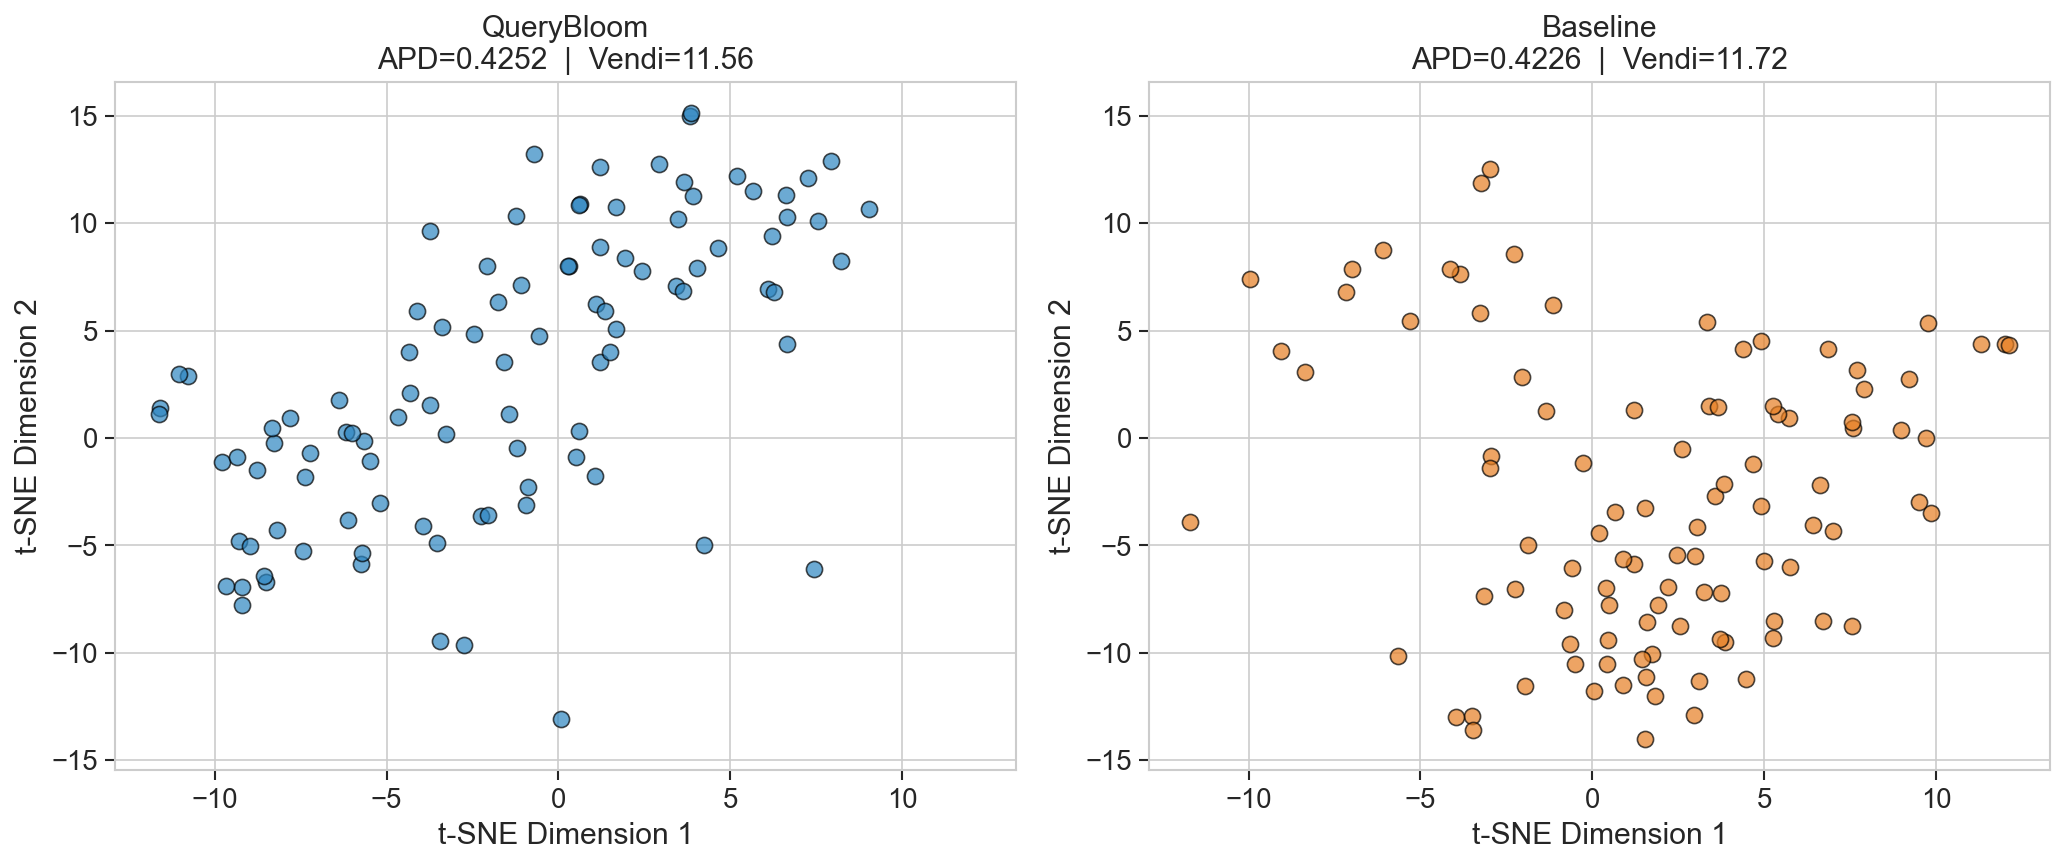

In [35]:
plot_semantic_embeddings(div1, div2, label1, label2, trim_outlier_pct=1)

## Figure 2 — Structural & Complexity Diversity

Three panels: (a) SPARQL feature distribution bars, (b) complexity-spread violins, (c) template / entity diversity scalars.

/Users/essamwisam/Desktop/UTA/Projects/NL2SparQL/misc/grasp/ABSTAT/analyze/plots/diversity_plots.py:542: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  mpatches.Patch(color=COLORS[1], alpha=0.85, label=label2),


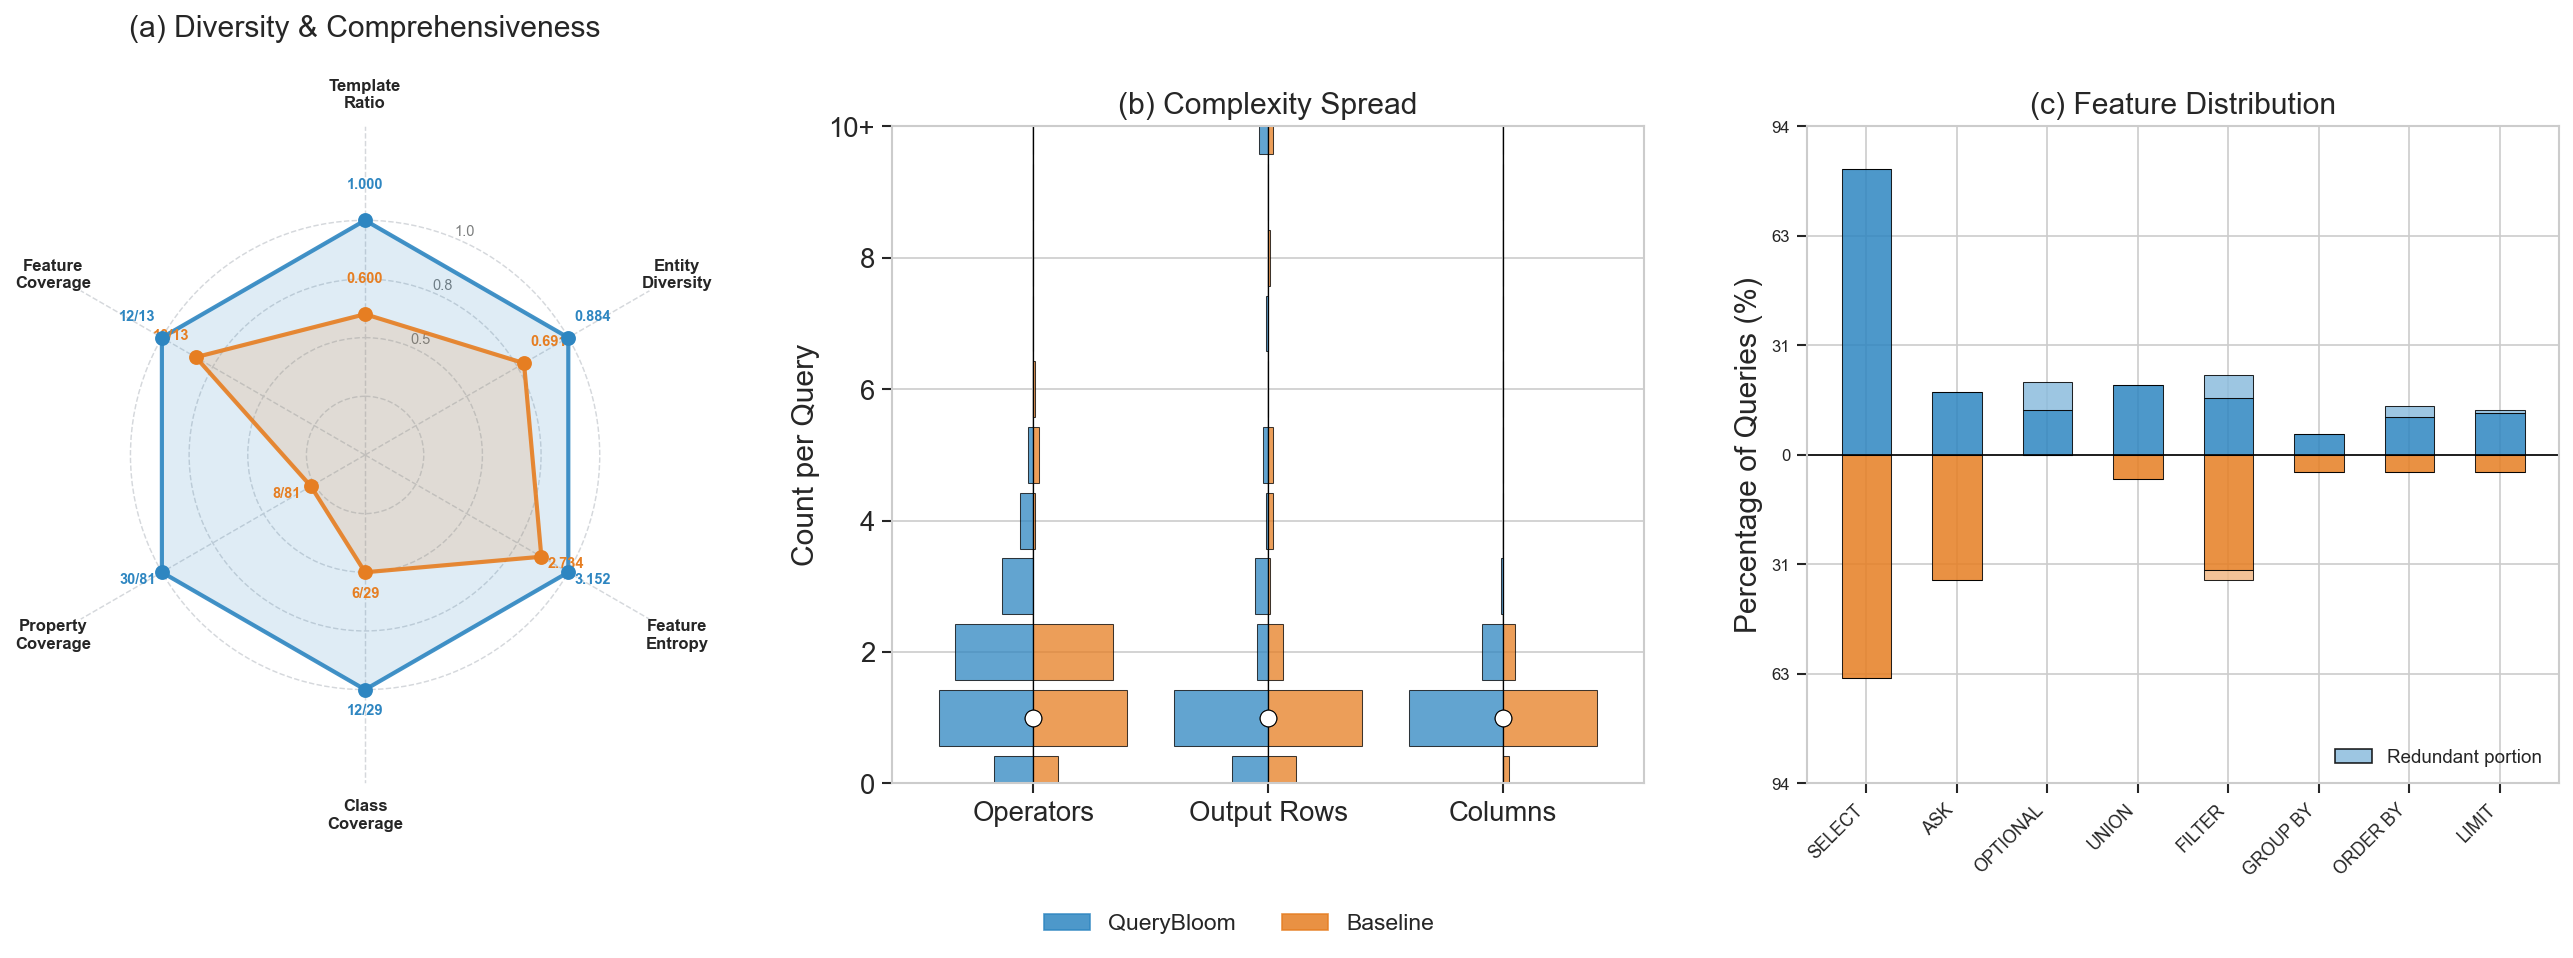

In [36]:
plot_structural_diversity(div1, div2, label1, label2, red1=red1, red2=red2, complexity_spread="histogram", comp1=comp1, comp2=comp2)

## Figure 3 — Comprehensiveness Radar

3-spoke radar showing Class Coverage, Property Coverage, and Feature Coverage against the KG ontology.

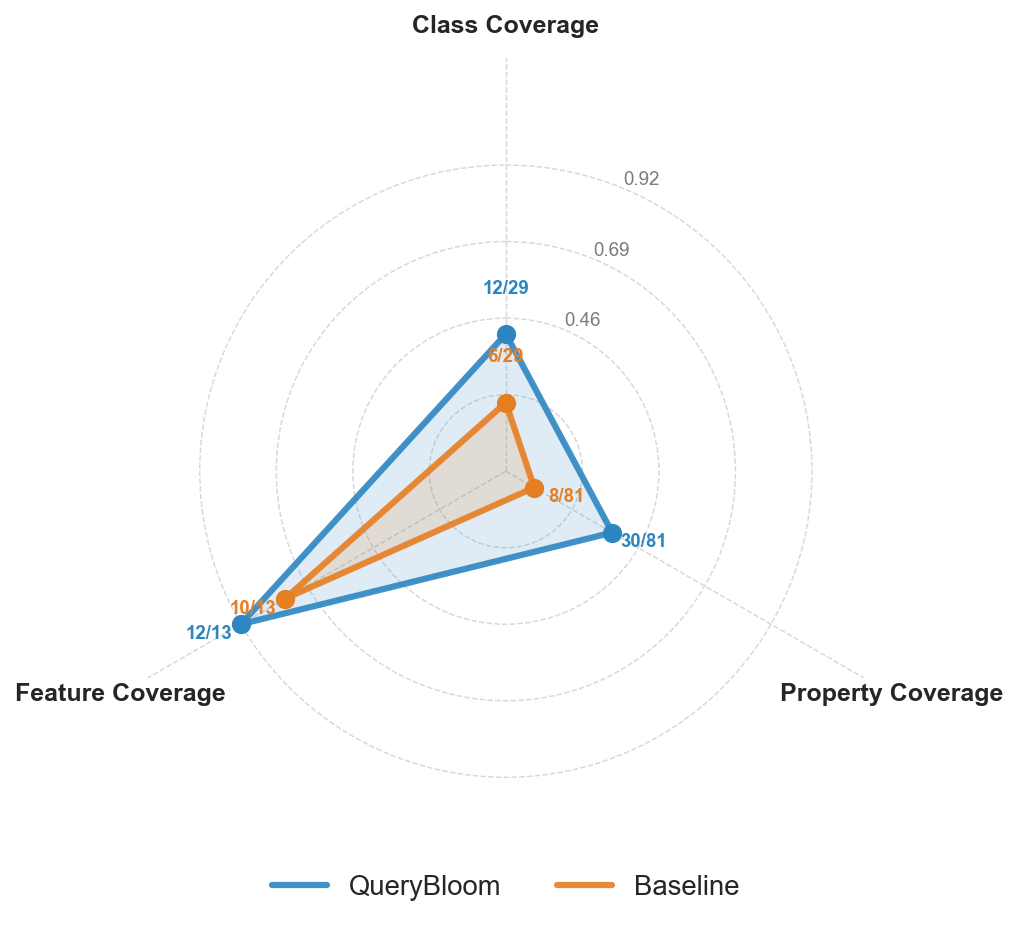

In [10]:
plot_comprehensiveness_radar(comp1, comp2, label1, label2)

## Figure 3b — Coverage Gaps Table

Random sample of classes and properties unique to one benchmark or missing from both.

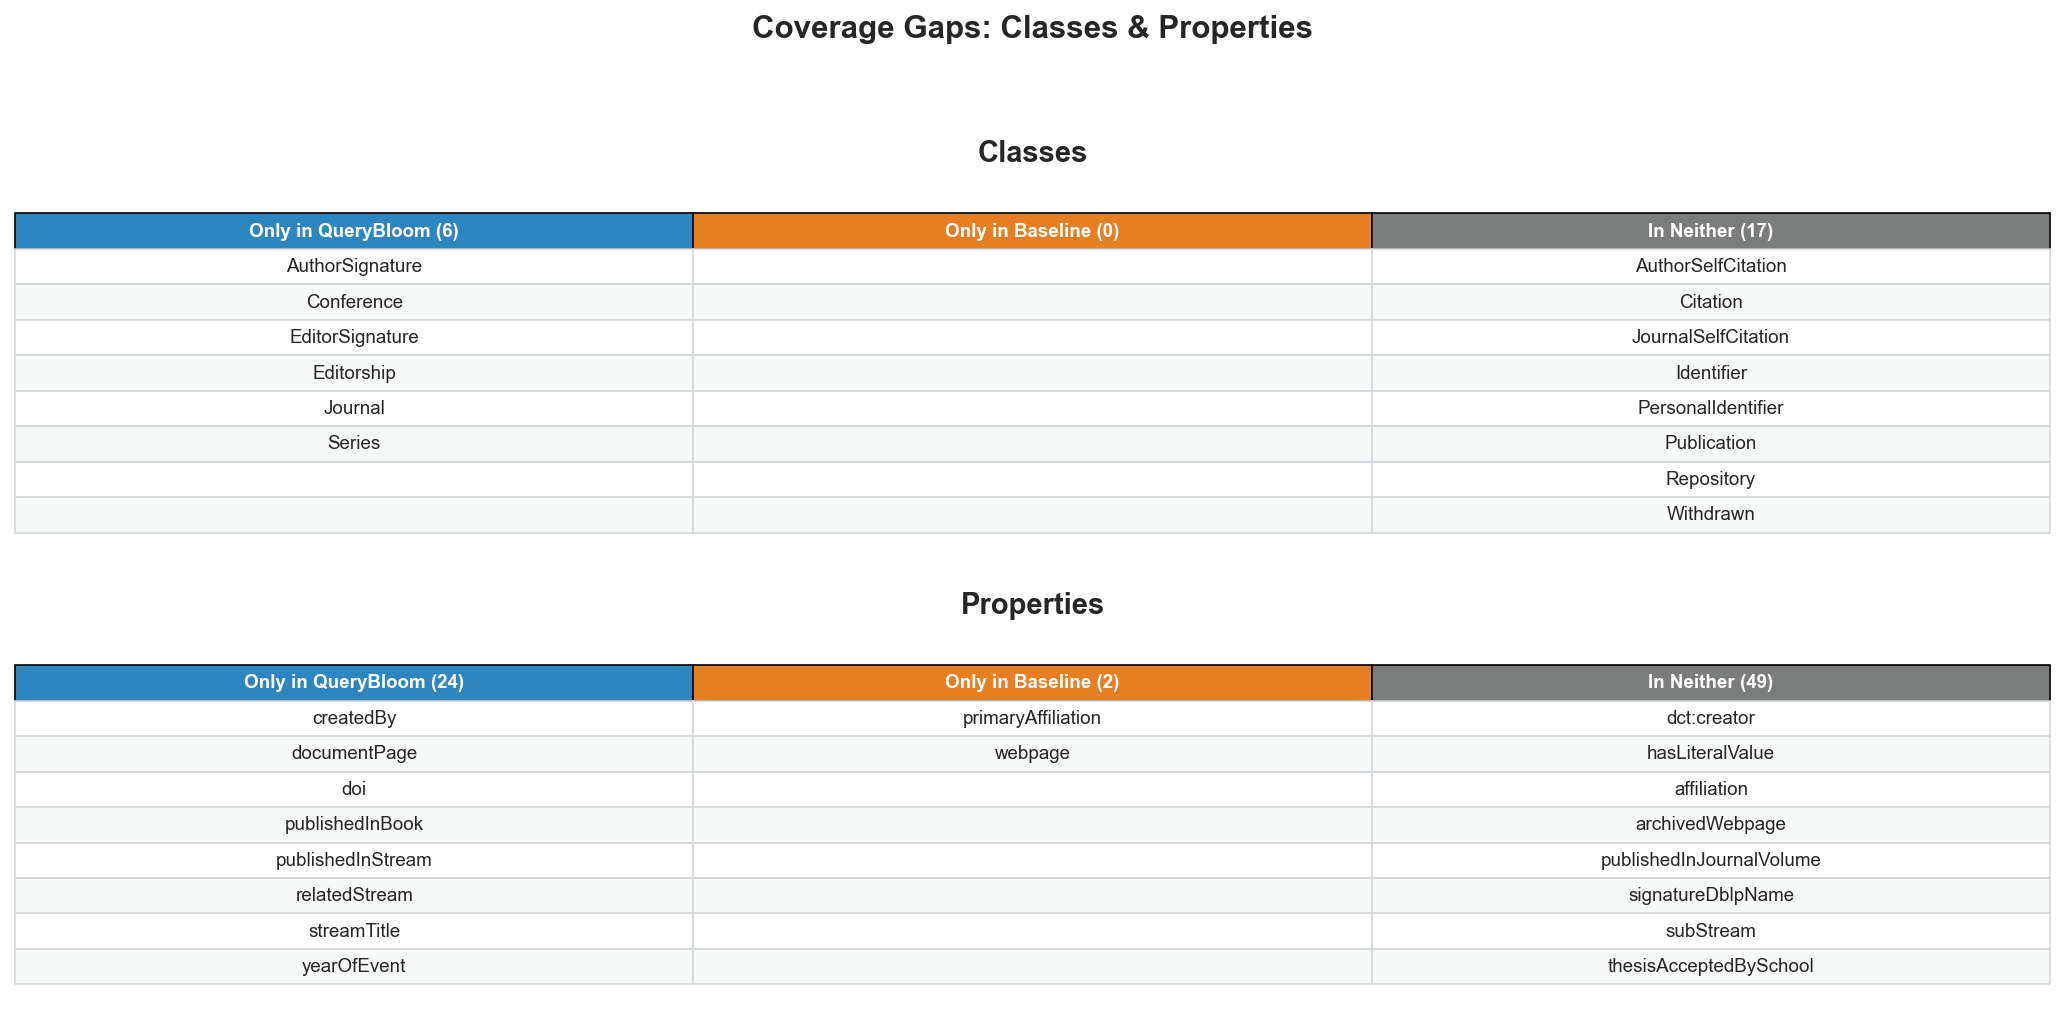

In [11]:
plot_coverage_table(queries1, queries2, kg_name, label1, label2, endpoint=endpoint)

In [12]:
from metrics.parsing import parse_and_extract_rdflib_metrics

# Look for rdf:type as a *property* in QueryBloom but not Baseline
target = "http://www.w3.org/1999/02/22-rdf-syntax-ns#type"

for label, queries in [(label1, queries1), (label2, queries2)]:
    count = 0
    for i, q in enumerate(queries):
        m = parse_and_extract_rdflib_metrics(q, endpoint=endpoint)
        if target in m["properties"]:
            count += 1
            if count <= 2:
                print(f"=== {label} query #{i} ===")
                print(q[:400])
                print("...\n")
    print(f"{label}: {count} queries have rdf:type as a property\n")

=== QueryBloom query #0 ===
PREFIX dblp: <https://dblp.org/rdf/schema#> PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#> SELECT ?label ?docPage WHERE { ?pub a dblp:Informal ; dblp:publishedIn "CoRR" ; dblp:authoredBy ?creator ; rdfs:label ?label . ?creator a dblp:AmbiguousCreator ; dblp:primaryCreatorName "Yi Bai" . OPTIONAL { ?pub dblp:primaryDocumentPage ?docPage . } }
...

=== QueryBloom query #1 ===
PREFIX dblp: <https://dblp.org/rdf/schema#>
SELECT ?title ?docPage WHERE {
  ?pub a dblp:Informal ;
       dblp:publishedIn "CoRR" ;
       dblp:title ?title ;
       dblp:authoredBy ?person .
  ?person a dblp:Person ;
          dblp:primaryCreatorName "Zicheng Qiu" .
  OPTIONAL { ?pub dblp:primaryDocumentPage ?docPage }
}
...

QueryBloom: 91 queries have rdf:type as a property

Baseline: 0 queries have rdf:type as a property



In [13]:
from plots import plot_semantic_embeddings, plot_structural_diversity, plot_comprehensiveness_radar, plot_redundancy, plot_coverage_table, show_redundancy_examples


show_redundancy_examples(queries1, questions1, query_endpoint)

Detecting redundant queries …
  Running / loading 107 unique queries …


NL Question,SPARQL Query
How many informal publications published in CoRR are authored by Songyuan Li?,"PREFIX dblp: <https://dblp.org/rdf/schema#> SELECT (COUNT(?informal) AS ?count) WHERE { ?informal a dblp:Informal ; dblp:authoredBy <https://dblp.org/pid/160/2310> ; dblp:publishedIn ?venue . FILTER(?venue = ""CoRR"") }"
Which proceedings of the 'International Conference on Smart Cities (Smart-CT)' contain more than 10 published papers?,PREFIX dblp: <https://dblp.org/rdf/schema#> SELECT ?editorship ?paperCount WHERE { { SELECT ?editorship (COUNT(?paper) AS ?paperCount) WHERE { ?editorship dblp:publishedInStream <https://dblp.org/streams/conf/smartct> . ?paper dblp:publishedAsPartOf ?editorship . } GROUP BY ?editorship } FILTER(?paperCount > 10) }
How many papers did Jingtao Du author in 2018 or later?,"PREFIX dblp: <https://dblp.org/rdf/schema#> SELECT (COUNT(?paper) AS ?paperCount) WHERE { ?paper a dblp:Inproceedings ; dblp:authoredBy ?person ; dblp:yearOfEvent ?year . ?person a dblp:Person ; dblp:primaryCreatorName ""Jingtao Du"" . FILTER(str(?year) >= ""2018"") }"
How many articles published in or after the year 2010 are attributed to the ambiguous author profile 'Martin Albrecht'?,"PREFIX dblp: <https://dblp.org/rdf/schema#> PREFIX xsd: <http://www.w3.org/2001/XMLSchema#> SELECT (COUNT(?article) AS ?count) WHERE { ?ambig a dblp:AmbiguousCreator ; dblp:primaryCreatorName ""Martin Albrecht"" . ?article a dblp:Article ; dblp:createdBy ?ambig ; dblp:yearOfPublication ?year . FILTER(xsd:integer(?year) >= 2010) }"
NL Question,SPARQL Query
"What are the titles of the proceedings that contain papers authored by Mehmet Aci, and what series are those proceedings published in, if available?","PREFIX dblp: <https://dblp.org/rdf/schema#> PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#> SELECT DISTINCT ?proceedingsLabel ?series WHERE { ?person a dblp:Person ; dblp:creatorname ""Mehmet Aci"" . ?paper a dblp:Inproceedings ; dblp:authoredBy ?person ; dblp:publishedAsPartOf ?proceedings . ?proceedings a dblp:Editorship ; rdfs:label ?proceedingsLabel . OPTIONAL { ?proceedings dblp:publishedInSeries ?series . } }"
"Which journals are related to the series 'Springer Tracts in Advanced Robotics (STAR)', and what are their Wikipedia links, if available?","PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#> PREFIX dblp: <https://dblp.org/rdf/schema#> SELECT ?journalLabel ?wiki WHERE { ?journal a dblp:Journal ; rdfs:label ?journalLabel ; dblp:relatedStream ?series . ?series a dblp:Series ; rdfs:label ""Springer Tracts in Advanced Robotics (STAR)"" . OPTIONAL { ?journal dblp:wikipedia ?wiki . } }"
"Which conference papers were authored by Satyam Kumar? Return their titles and, if available, the venues they were published in.","PREFIX dblp: <https://dblp.org/rdf/schema#> SELECT ?title ?venue WHERE { ?creator a dblp:AmbiguousCreator ; dblp:primaryCreatorName ""Satyam Kumar"" . ?signature a dblp:AuthorSignature ; dblp:signatureCreator ?creator ; dblp:signaturePublication ?paper . ?paper a dblp:Inproceedings ; dblp:title ?title . OPTIONAL { ?paper dblp:publishedIn ?venue } }"
"What are the primary titles and, if available, the ISSNs of the series that include publications edited by the creator with the ambiguous profile 'Lin Zhao'?","PREFIX dblp: <https://dblp.org/rdf/schema#> SELECT DISTINCT ?seriesTitle ?issn WHERE { ?creator a dblp:AmbiguousCreator ; dblp:primaryCreatorName ""Lin Zhao"" . ?editorship a dblp:Editorship ; dblp:editedBy ?creator ; dblp:publishedInStream ?series . ?series a dblp:Series ; dblp:primaryStreamTitle ?seriesTitle . OPTIONAL { ?series dblp:issn ?issn . } }"
What are the primary names and any alternative names of the authors of the article titled 'Siegfried Gottwald and Stephan Lehmke: Obituary: Professor Dr. Helmut Thiele (1926-2003). (2004)'?,"PREFIX dblp: <https://dblp.org/rdf/schema#> PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#> SELECT ?creatorName ?altName WHERE { ?article a dblp:Article ; rdfs:label ""Siegf

Done.
